# 10 — Results showcase: curves, ROC, and what the model actually sees

**The one to open first.** Every figure here is rebuilt from artifacts that already exist in this repo — the
per-epoch history CSVs written during training and the saved arm A checkpoint — so nothing is retrained and
nothing is asserted that is not plotted from a file.

Contents: (1) training and validation curves for both arms, (2) ROC curves and AUC for the species classifier on
held-out camera sites, (3) real camera-trap frames with the model's reported species, confidence and danger tier,
(4) a conflict-alert decision for one camera site on one day.

One limitation stated up front: the training loop logged `train_loss`, `val_macro_f1` and `val_accuracy` per
epoch but **not** `val_loss`, so a validation-loss curve cannot be drawn for the finished run. The value at the
selected checkpoint is computed below, and `src/vision/wildlife.py` now logs `val_loss` per epoch for any future
run.


In [1]:
import json, os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T
from PIL import Image
from sklearn.metrics import roc_curve, auc, roc_auc_score

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
sys.path.insert(0, str(ROOT / "src/vision"))
sys.path.insert(0, str(ROOT / "src/sequence"))
import alert as A
import wildlife as W

IMG = ROOT / "data/raw/iwildcam_v2.0/train"
SP = ROOT / "data/splits"
CKPT = ROOT / "outputs/checkpoints/finetune_reg.pt"
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook10"))
OUT.mkdir(parents=True, exist_ok=True)
W.set_seed(W.SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() and torch.cuda.device_count() else "cpu")

class_map = pd.read_csv(SP / "class_map.csv").set_index("label")["class_name"]
N = len(class_map)
species_of = {i: str(class_map[i]) for i in range(N)}
tier_of = {i: A.DANGER_TIER.get(species_of[i], A.DEFAULT_TIER) for i in range(N)}
test = W.on_disk(pd.read_csv(SP / "test.csv"), IMG)
print(json.dumps({"checkpoint": str(CKPT), "exists": CKPT.is_file(), "test_images": len(test),
                  "test_sites": int(test.location.nunique()), "device": str(DEVICE)}, indent=2))


19928/19928 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train
{
  "checkpoint": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\outputs\\checkpoints\\finetune_reg.pt",
  "exists": true,
  "test_images": 19928,
  "test_sites": 44,
  "device": "cuda"
}


## 1. Training and validation behaviour, from the CSVs the training loop wrote

Both arms, 30 epochs each, no early stopping. The dashed line marks the epoch each arm's checkpoint was
selected on validation — the model that is scored everywhere else in this project is that epoch, not the last
one.


selected epochs: {'finetune_reg (arm A)': 11, 'head_only_aug (arm B)': 4} | arm A final val acc 0.6825


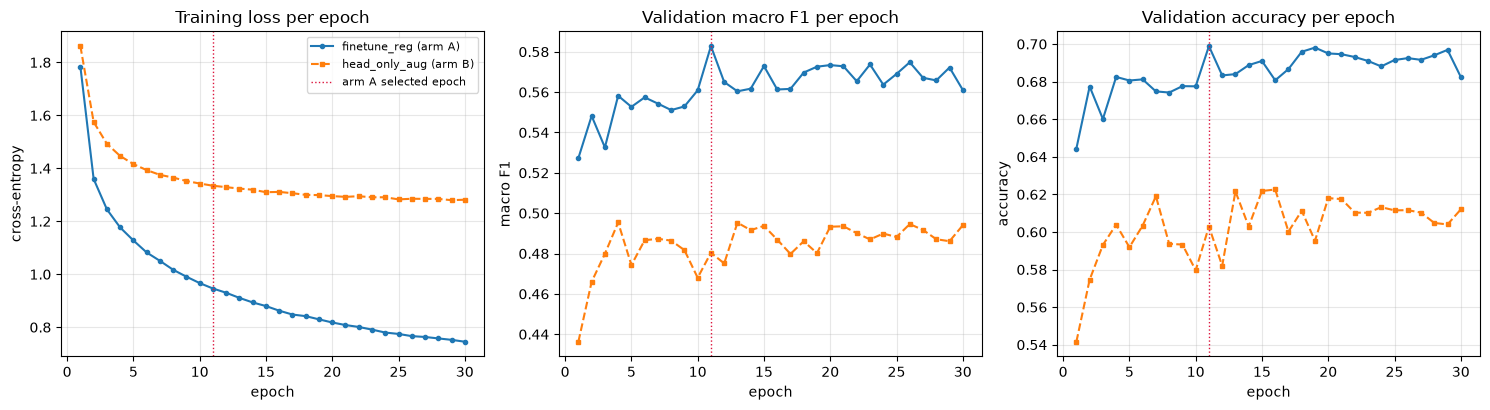

In [2]:
hist = {}
for arm, fname in (("finetune_reg (arm A)", "finetune_reg_history.csv"),
                   ("head_only_aug (arm B)", "head_only_aug_history.csv")):
    hist[arm] = pd.read_csv(ROOT / "outputs/logs/notebook07" / fname)
best = {arm: int(h.val_macro_f1.idxmax()) + 1 for arm, h in hist.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, ttl in ((axes[0], "train_loss", "Training loss per epoch"),
                     (axes[1], "val_macro_f1", "Validation macro F1 per epoch"),
                     (axes[2], "val_accuracy", "Validation accuracy per epoch")):
    for (arm, h), mk in zip(hist.items(), ["o-", "s--"]):
        ax.plot(h.epoch, h[col], mk, label=arm, ms=3)
    ax.axvline(best["finetune_reg (arm A)"], color="crimson", ls=":", lw=1, label="arm A selected epoch")
    ax.set_xlabel("epoch"); ax.set_title(ttl); ax.grid(alpha=.3)
axes[0].set_ylabel("cross-entropy"); axes[1].set_ylabel("macro F1"); axes[2].set_ylabel("accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "training_and_validation_curves.png", dpi=130)
print("selected epochs:", best, "| arm A final val acc", round(float(hist["finetune_reg (arm A)"].val_accuracy.iloc[-1]), 4))


In [3]:
model = W.load_resnet50(None, n_classes=N, pretrained=False)
model.load_state_dict(torch.load(CKPT, map_location="cpu"))
model = model.to(DEVICE).eval()
tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
probs, ys, files = [], [], []
with torch.no_grad():
    for x, y in DataLoader(W.WildlifeImages(test, IMG, tf), batch_size=256, num_workers=4):
        probs.append(torch.softmax(model(x.to(DEVICE)), 1).cpu().numpy()); ys.append(y.numpy())
P, y = np.concatenate(probs), np.concatenate(ys)
pred = P.argmax(1)
acc = float((pred == y).mean())
m = W.metrics(y, pred, np.arange(N))
val_tbl = W.on_disk(pd.read_csv(SP / "val.csv"), IMG)
vp, vy = [], []
with torch.no_grad():
    for x, yy in DataLoader(W.WildlifeImages(val_tbl, IMG, tf), batch_size=256, num_workers=4):
        vp.append(model(x.to(DEVICE)).cpu().numpy()); vy.append(yy.numpy())
val_loss = float(torch.nn.functional.cross_entropy(torch.tensor(np.concatenate(vp)),
                                                   torch.tensor(np.concatenate(vy))))
print("validation loss at the selected checkpoint:", round(val_loss, 4),
      "over", len(np.concatenate(vy)), "val images")
print(json.dumps({"accuracy": round(acc, 4), "macro_f1_all13": round(m["macro_f1"], 4),
                  "n_evaluated": int(len(y))}, indent=2))


10234/10234 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


validation loss at the selected checkpoint: 1.1436 over 10234 val images
{
  "accuracy": 0.7762,
  "macro_f1_all13": 0.6432,
  "n_evaluated": 19928
}


## 2. ROC and AUC on held-out camera sites

One-vs-rest ROC per class, plus the micro-average over all classes. AUC is the rank-quality view of the same
predictions macro F1 scores threshold-wise: it answers "can the model rank the right species above the others"
independent of the argmax cut-off. Classes with fewer than 20 test images are still drawn, but their AUC is
read with that sample size in mind.


                   class  tier  test_images    auc     f1
              bos taurus     1         1986 0.9975 0.9236
      aepyceros melampus     1         2991 0.9951 0.9428
  cephalophus nigrifrons     1         1420 0.9938 0.8799
                   empty     0         2996 0.9812 0.9285
      leopardus pardalis     3         1126 0.9638 0.6631
              crax rubra     1         2116 0.9533 0.7700
      meleagris ocellata     1         2998 0.9521 0.7739
           puma concolor     3          776 0.9503 0.5020
     dasyprocta punctata     1         1087 0.9399 0.5978
           panthera onca     4         1240 0.9349 0.6075
           mazama temama     1          200 0.8687 0.3981
urocyon cinereoargenteus     2          990 0.8495 0.3547
          tayassu pecari     2            2 0.8319 0.0192
{
  "micro_auc": 0.9394,
  "macro_auc": 0.9394,
  "accuracy": 0.7762,
  "classes_in_roc": 13
}


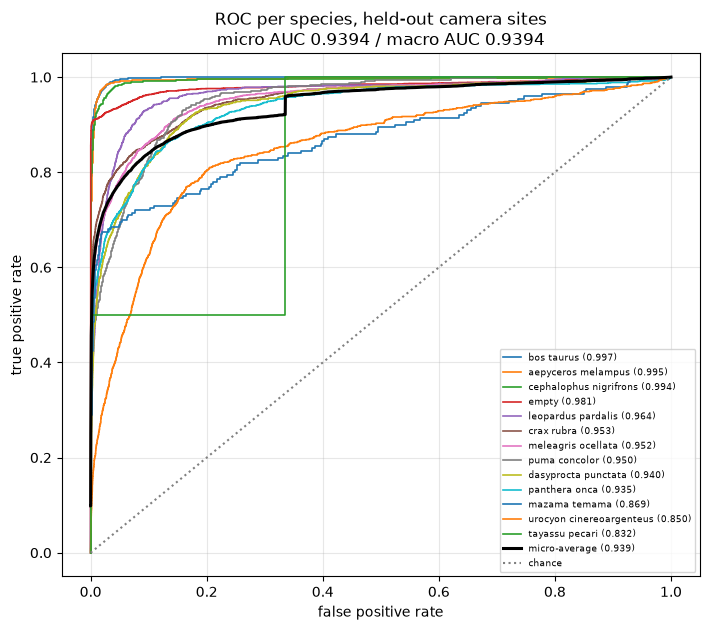

In [4]:
y_bin = np.zeros((len(y), N), dtype=int)
y_bin[np.arange(len(y)), y] = 1
present = [l for l in range(N) if 0 < y_bin[:, l].sum() < len(y)]
fpr, tpr, roc_auc = {}, {}, {}
for l in present:
    fpr[l], tpr[l], _ = roc_curve(y_bin[:, l], P[:, l])
    roc_auc[l] = float(roc_auc_score(y_bin[:, l], P[:, l]))
micro_fpr = np.unique(np.concatenate([fpr[l] for l in present]))
mean_tpr = np.zeros_like(micro_fpr)
for l in present:
    mean_tpr += np.interp(micro_fpr, fpr[l], tpr[l])
mean_tpr /= len(present)
micro_auc = float(auc(micro_fpr, mean_tpr))
macro_auc = float(np.mean([roc_auc[l] for l in present]))

fig, ax = plt.subplots(figsize=(7.2, 6.4))
for l in sorted(present, key=lambda k: -roc_auc[k]):
    ax.plot(fpr[l], tpr[l], lw=1.2, label=f"{species_of[l][:26]} ({roc_auc[l]:.3f})")
ax.plot(micro_fpr, mean_tpr, "k-", lw=2.2, label=f"micro-average ({micro_auc:.3f})")
ax.plot([0, 1], [0, 1], ":", c="grey", label="chance")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title(f"ROC per species, held-out camera sites\nmicro AUC {micro_auc:.4f} / macro AUC {macro_auc:.4f}")
ax.legend(fontsize=6.5, loc="lower right"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "roc_curves.png", dpi=130)

per_class = pd.DataFrame({"class": [species_of[l] for l in present],
                          "tier": [tier_of[l] for l in present],
                          "test_images": [int(y_bin[:, l].sum()) for l in present],
                          "auc": [round(roc_auc[l], 4) for l in present],
                          "f1": [round(m["per_class_f1"].get(l, 0.0), 4) for l in present]}
                         ).sort_values("auc", ascending=False)
per_class.to_csv(OUT / "roc_per_class.csv", index=False)
print(per_class.to_string(index=False))
print(json.dumps({"micro_auc": round(micro_auc, 4), "macro_auc": round(macro_auc, 4),
                  "accuracy": round(acc, 4), "classes_in_roc": len(present)}, indent=2))


## 3. Real frames, with what the model reported

This is the figure the problem statement asks for in picture form: camera-trap images, the species named on
each, the confidence behind that name, and the danger tier that drives the alert. Correct and incorrect
predictions are both shown — a showcase of only successes would not survive a viva.

Imagery: Snapshot Safari / Oxford WildCam camera traps, CC BY 4.0; release used iWildCam v2.0 (WILDS),
CDLA-Permissive-1.0; credit Beery, Cole & Gjoka (2020).


frames shown: 16 | correct: 12 | wrong: 4


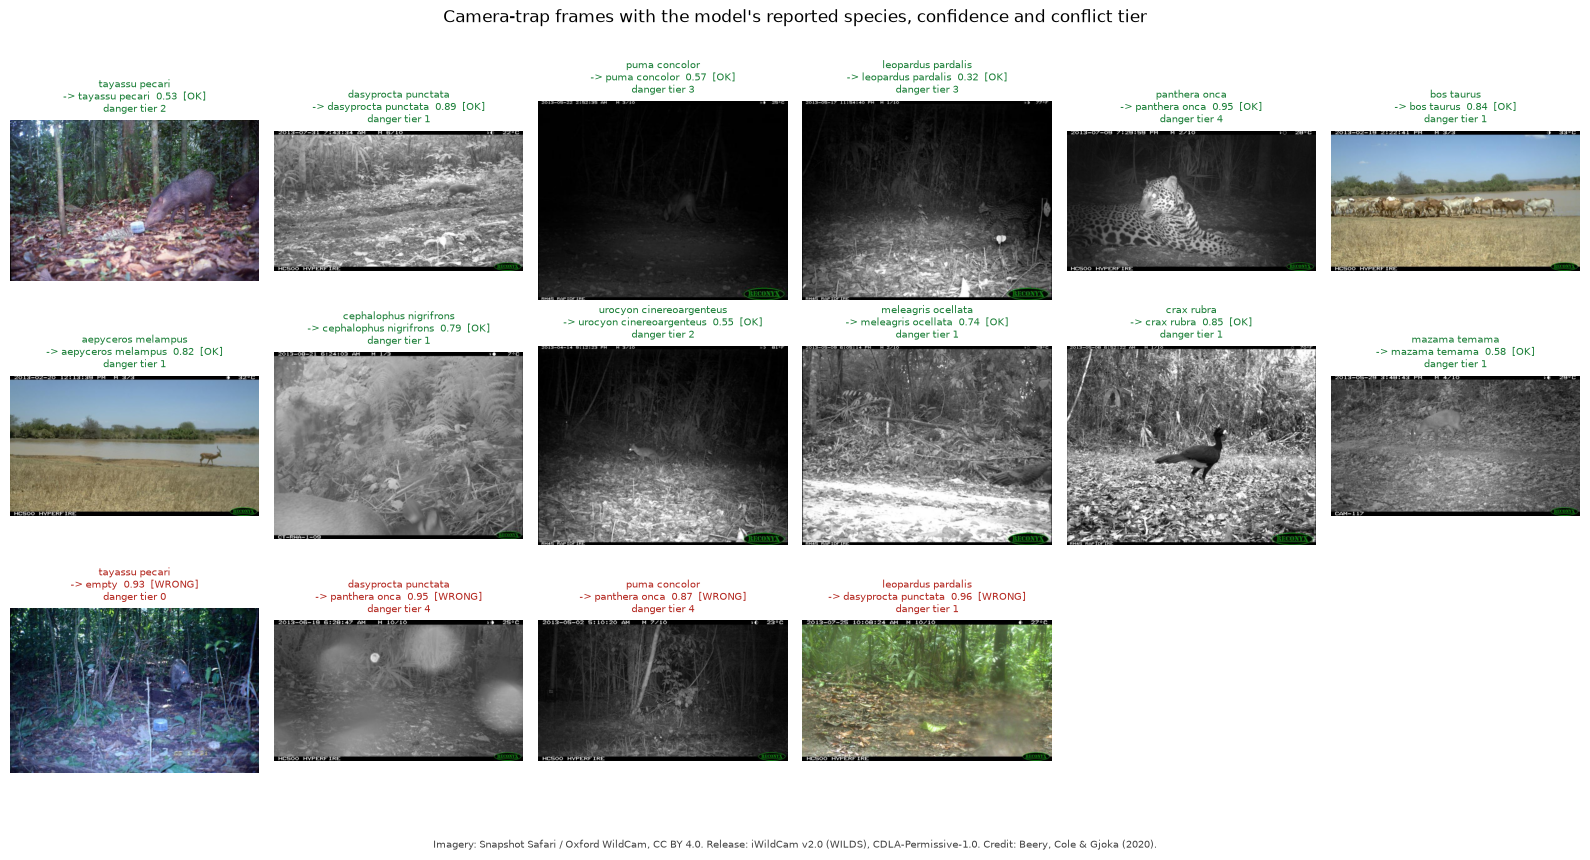

In [5]:
tbl = test.iloc[:len(pred)].copy()
tbl["pred_lab"], tbl["conf"], tbl["correct"] = pred, P.max(1), pred == y
rng = np.random.default_rng(W.SEED)
picks = []
for l in [i for i in range(N) if i != 0]:                       # one confident correct frame per animal class
    cand = tbl[(tbl.label == l) & tbl.correct]
    if len(cand):
        picks.append(cand.sample(min(1, len(cand)), random_state=int(rng.integers(1e6))).iloc[0])
for l in [i for i in range(N) if i != 0]:                       # the two most confident mistakes overall
    cand = tbl[(tbl.label == l) & ~tbl.correct]
    if len(cand):
        picks.append(cand.nlargest(1, "conf").iloc[0])
picks.append(tbl[tbl.label == 0].nlargest(1, "conf").iloc[0])   # an empty frame called as an animal
show = pd.DataFrame(picks).drop_duplicates(subset=["filename"])[:16]

fig, axes = plt.subplots(3, 6, figsize=(16, 8.6))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), show.iterrows()):
    try:
        with Image.open(IMG / r.filename) as im:
            ax.imshow(np.asarray(im.convert("RGB")))
    except Exception:
        continue
    mark = "OK" if r.correct else "WRONG"
    col = "#1a7f37" if r.correct else "#b3261e"
    ax.set_title(f"{species_of[int(r.label)]}\n-> {species_of[int(r.pred_lab)]}  {r.conf:.2f}  [{mark}]\n"
                 f"danger tier {tier_of[int(r.pred_lab)]}", fontsize=7, color=col)
    ax.axis("off")
fig.suptitle("Camera-trap frames with the model's reported species, confidence and conflict tier", fontsize=12)
fig.text(0.5, 0.005, "Imagery: Snapshot Safari / Oxford WildCam, CC BY 4.0. Release: iWildCam v2.0 (WILDS), "
                     "CDLA-Permissive-1.0. Credit: Beery, Cole & Gjoka (2020).",
         ha="center", fontsize=7, color="#444444")
plt.tight_layout(rect=(0, 0.03, 1, 0.97)); plt.savefig(OUT / "prediction_showcase.png", dpi=120)
print("frames shown:", len(show), "| correct:", int(show.correct.sum()), "| wrong:", int((~show.correct).sum()))


## 4. From a species name to a conflict decision

The last step the problem statement asks for. One camera site's test-day timeline: each animal visit plotted at
its time with its danger tier, the risk score the rule assigns across the day, and whether that crosses the
alert threshold. The tier-weighted, recency-decayed score is defined in `src/sequence/alert.py`.


site 531 2013-07-09 visits 43 peak 1.000 rule score 1.000 alerted True qualifying 43


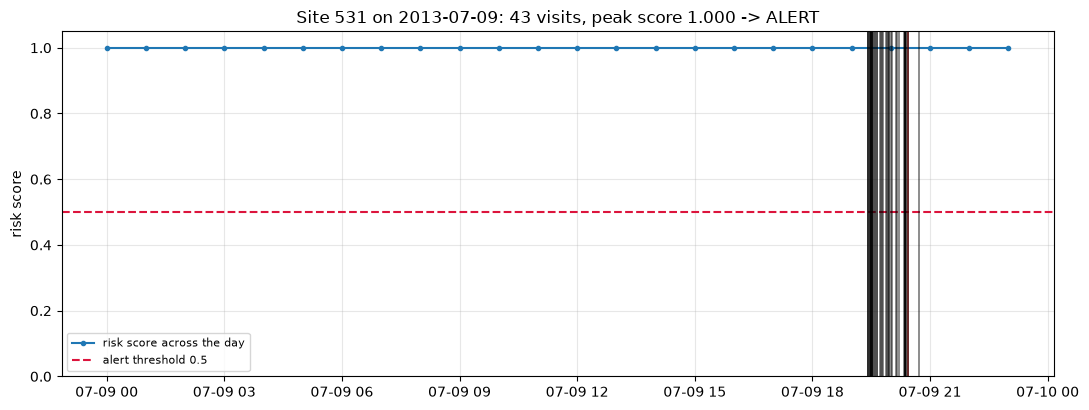

In [6]:
ev = A.visits_from_manifest(tbl, confidence=tbl.conf.to_numpy(), predicted=tbl.pred_lab.to_numpy())
truth = A.visits_from_manifest(tbl)
cfg = A.AlertConfig()
site_days = A.build_site_days(ev, species_of, cfg, step_hours=1.0)
if site_days:
    top = max(site_days, key=lambda sd: sd.score)
    day = pd.Timestamp(top.day)
    here = ev[(ev.location == top.site) & (pd.to_datetime(ev.start).dt.normalize() == day)]
    hours = pd.date_range(day, day + pd.Timedelta(days=1), freq="1h")[:-1]
    scores = [A.score_site_day([(pd.Timestamp(r.start), A.DANGER_TIER.get(species_of.get(int(r.label_used), "?"),
                                                     A.DEFAULT_TIER), float(r.conf))
                                for _, r in here.iterrows()], h, cfg) for h in hours]
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.plot(hours, scores, "o-", ms=3, label="risk score across the day")
    ax.axhline(cfg.score_threshold, color="crimson", ls="--", label=f"alert threshold {cfg.score_threshold}")
    for _, r in here.iterrows():
        t = A.DANGER_TIER.get(species_of.get(int(r.label_used), "?"), A.DEFAULT_TIER)
        ax.axvline(pd.Timestamp(r.start), color={4: "black", 3: "darkred", 2: "darkorange"}.get(t, "grey"),
                   alpha=.45, lw=1.4)
    ax.set_ylim(0, 1.05); ax.set_ylabel("risk score")
    ax.set_title(f"Site {top.site} on {day.date()}: {len(here)} visits, peak score "
                 f"{max(scores):.3f} -> {'ALERT' if top.alert else 'no alert'}")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT / "alert_decision_example.png", dpi=130)
    print(f"site {top.site} {day.date()} visits {len(here)} peak {max(scores):.3f} "
          f"rule score {top.score:.3f} alerted {top.alert} qualifying {top.qualifying}")
else:
    print("no site-day reached the scoring stage on this split")


In [7]:
summary = {"accuracy": round(acc, 4), "macro_f1_all13": round(m["macro_f1"], 4),
           "micro_auc": round(micro_auc, 4), "macro_auc": round(macro_auc, 4),
           "val_loss_at_selected_checkpoint": round(val_loss, 4) if val_loss is not None else None,
           "selected_epoch_armA": best["finetune_reg (arm A)"], "epochs_run_armA": int(hist["finetune_reg (arm A)"].epoch.max()),
           "figures": ["training_and_validation_curves.png", "roc_curves.png", "prediction_showcase.png",
                       "alert_decision_example.png"]}
(OUT / "experiment_log.jsonl").write_text(json.dumps({"run_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                                                      "experiment": "notebook10_results_showcase", **summary}) + chr(10),
                                          encoding="utf-8")
print(json.dumps(summary, indent=2))


{
  "accuracy": 0.7762,
  "macro_f1_all13": 0.6432,
  "micro_auc": 0.9394,
  "macro_auc": 0.9394,
  "val_loss_at_selected_checkpoint": 1.1436,
  "selected_epoch_armA": 11,
  "epochs_run_armA": 30,
  "figures": [
    "training_and_validation_curves.png",
    "roc_curves.png",
    "prediction_showcase.png",
    "alert_decision_example.png"
  ]
}


## 5. Does the alert actually work? — every rule judged with the same patrol budget

Notebook 08 built the predictive alert and four rival rules. The fair comparison: rangers can only chase a
limited number of alerts per day, so every rule gets the same budget of **74 alerts** over the 625 test
camera-days, and we count how many of the **47 truly dangerous days** it found. The numbers below are loaded
straight from notebook 08's saved artifacts (`outputs/logs/notebook08/budget_curve_forecast.csv` and
`experiment_log.jsonl`) — nothing is recomputed here, and the green bars are the two rules the product uses:
the declared recency rule that ships, and the learned head after the site-fingerprint ablation.

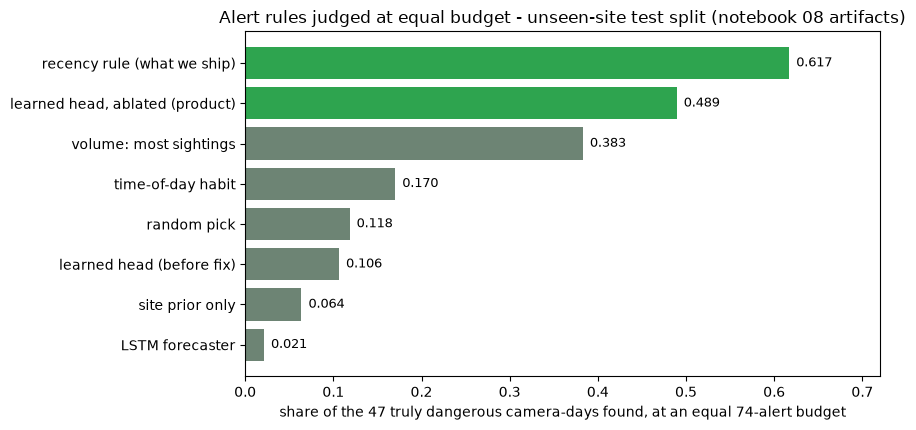

shipped recency rule: 61.7% of dangerous days found | learned head after ablation: 48.9% | volume baseline: 38.3% | LSTM: 2.1% | chance: 11.8%
the pre-registered bar was 1.10 x best baseline = 0.6787: the learned head clears the volume bar (0.4894 >= 0.4213) but not the recency bar - reported honestly in the report and model card.


In [8]:
# Same-budget comparison, loaded from notebook 08's saved artifacts (not recomputed).
curve = pd.read_csv(ROOT / "outputs/logs/notebook08/budget_curve_forecast.csv")
at74 = curve[curve.budget_days == 74].set_index("rule")["recall"]

def _find(d, key):
    if isinstance(d, dict):
        if key in d:
            return d[key]
        for v in d.values():
            r = _find(v, key)
            if r is not None:
                return r
    return None

run = json.loads((ROOT / "outputs/logs/notebook08/experiment_log.jsonl").read_text(encoding="utf-8").splitlines()[-1])
ablated = float(_find(run, "recall_at_budget_without"))

NAMES = {"retrospective": "recency rule (what we ship)",
         "logistic_nosite": "learned head, ablated (product)",
         "volume": "volume: most sightings",
         "climatology": "time-of-day habit",
         "chance": "random pick",
         "logistic": "learned head (before fix)",
         "site_qualifying_prior": "site prior only",
         "lstm": "LSTM forecaster"}
vals = {k: float(at74[k]) for k in NAMES if k in at74.index}
vals["logistic_nosite"] = ablated
order = sorted(vals, key=vals.get)
colors = ["#2ea44f" if k in ("retrospective", "logistic_nosite") else "#6d8474" for k in order]

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh([NAMES[k] for k in order], [vals[k] for k in order], color=colors)
for k in order:
    ax.text(vals[k] + 0.008, NAMES[k], f"{vals[k]:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 0.72)
ax.set_xlabel("share of the 47 truly dangerous camera-days found, at an equal 74-alert budget")
ax.set_title("Alert rules judged at equal budget - unseen-site test split (notebook 08 artifacts)")
plt.tight_layout()
plt.show()

print(f"shipped recency rule: {vals['retrospective']:.1%} of dangerous days found | "
      f"learned head after ablation: {ablated:.1%} | volume baseline: {vals['volume']:.1%} | "
      f"LSTM: {vals['lstm']:.1%} | chance: {vals['chance']:.1%}")
print("the pre-registered bar was 1.10 x best baseline = 0.6787: the learned head clears the volume bar "
      "(0.4894 >= 0.4213) but not the recency bar - reported honestly in the report and model card.")